In [ ]:
import os
import random
import time   # ⬅️ NEW
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torchvision.models import resnet50
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import kagglehub

torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [ ]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Dataset path:", path)


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset path: /kaggle/input/chest-xray-pneumonia


In [ ]:
data_root = Path(path)
base_dir = data_root / "chest_xray" if (data_root / "chest_xray").exists() else data_root

train_dir = base_dir / "train"
test_dir  = base_dir / "test"


In [ ]:
image_size = 224
batch_size = 64
num_workers = 4 if torch.cuda.is_available() else 2

train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],
                         std=[0.229,0.224,0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],
                         std=[0.229,0.224,0.225]),
])

In [ ]:
full_train_dataset = ImageFolder(train_dir, transform=train_transform)
targets = np.array(full_train_dataset.targets)
indices = np.arange(len(targets))

class_names = full_train_dataset.classes
num_classes = len(class_names)
print("Classes:", class_names)

normal_idx = indices[targets == 0]
pneumonia_idx = indices[targets == 1]

pneumonia_idx_down = np.random.choice(
    pneumonia_idx,
    size=len(normal_idx),
    replace=False
)

balanced_indices = np.concatenate([normal_idx, pneumonia_idx_down])
np.random.shuffle(balanced_indices)

train_idx, val_idx = train_test_split(
    balanced_indices,
    test_size=0.10,
    stratify=targets[balanced_indices],
    random_state=42
)

train_dataset = Subset(
    ImageFolder(train_dir, transform=train_transform),
    train_idx
)

val_dataset = Subset(
    ImageFolder(train_dir, transform=eval_transform),
    val_idx
)

test_dataset = ImageFolder(test_dir, transform=eval_transform)

print(f"Train size: {len(train_dataset)}")
print(f"Val size:   {len(val_dataset)}")
print(f"Test size:  {len(test_dataset)}")

print("Balanced train distribution:",
      np.bincount([targets[i] for i in train_idx]))

Classes: ['NORMAL', 'PNEUMONIA']
Train size: 2413
Val size:   269
Test size:  624
Balanced train distribution: [1206 1207]


In [ ]:
train_loader = DataLoader(
    train_dataset, batch_size=batch_size,
    shuffle=True, num_workers=num_workers
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size,
    shuffle=False, num_workers=num_workers
)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size,
    shuffle=False, num_workers=num_workers
)



/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [ ]:

backbone = resnet50(pretrained=False)
backbone.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)
backbone.maxpool = nn.Identity()
feat_dim = backbone.fc.in_features
backbone.fc = nn.Identity()

ckpt_path = hf_hub_download(
    repo_id="edadaltocg/resnet50_simclr_cifar100",
    filename="pytorch_model.bin"
)

state_dict = torch.load(ckpt_path, map_location="cpu")
state_dict = {
    k.replace("backbone.", ""): v
    for k, v in state_dict.items()
    if k.replace("backbone.", "") in backbone.state_dict()
}

backbone.load_state_dict(state_dict, strict=False)
backbone = backbone.to(device)
print("✅ CIFAR SimCLR backbone loaded")


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or 

pytorch_model.bin:   0%|          | 0.00/94.3M [00:00<?, ?B/s]

✅ CIFAR SimCLR backbone loaded


In [ ]:
class PartialFineTuneModel(nn.Module):
    def __init__(self, backbone, feature_dim, num_classes):
        super().__init__()
        self.backbone = backbone

        # Freeze entire backbone
        for p in self.backbone.parameters():
            p.requires_grad = False

        # Unfreeze only the last ResNet block (layer4)
        for p in self.backbone.layer4.parameters():
            p.requires_grad = True

        self.classifier = nn.Linear(feature_dim, num_classes)

    def forward(self, x):
        return self.classifier(self.backbone(x))

model = PartialFineTuneModel(backbone, feat_dim, num_classes).to(device)


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    [
        {"params": model.backbone.layer4.parameters(), "lr": 1e-4},
        {"params": model.classifier.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-6
)


In [ ]:
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)

            total_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
            total += xb.size(0)

    return total_loss / total, correct / total

In [ ]:
epochs = 6
train_losses, val_losses = [], []

start_time = time.time()
for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
    for xb, yb in pbar:
        xb, yb = xb.to(device), yb.to(device)

        logits = model(xb)
        loss = criterion(logits, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        pbar.set_postfix(train_loss=running_loss / (pbar.n + 1))

    train_loss = running_loss / len(train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1}: "
          f"Train Loss={train_loss:.4f}, "
          f"Val Loss={val_loss:.4f}, "
          f"Val Acc={val_acc:.4f}")
end_time = time.time()   # ⬅️ NEW
total_time = end_time - start_time

print("\n==============================")
print(f"Total training time: {total_time/60:.2f} minutes")
print(f"Average time per epoch: {total_time/epochs:.2f} seconds")
print("==============================\n")


Epoch 1/6: 100%|██████████| 38/38 [02:36<00:00,  4.11s/it, train_loss=0.36]


Epoch 1: Train Loss=0.3596, Val Loss=0.2937, Val Acc=0.6245


Epoch 2/6: 100%|██████████| 38/38 [02:39<00:00,  4.21s/it, train_loss=0.181]


Epoch 2: Train Loss=0.1813, Val Loss=0.1354, Val Acc=0.9554


Epoch 3/6: 100%|██████████| 38/38 [02:39<00:00,  4.19s/it, train_loss=0.0764]


Epoch 3: Train Loss=0.0764, Val Loss=0.0755, Val Acc=0.9628


... (2 outputs left out)

Epoch 5/6: 100%|██████████| 38/38 [02:40<00:00,  4.23s/it, train_loss=0.0235]


Epoch 5: Train Loss=0.0235, Val Loss=0.0420, Val Acc=0.9777


Epoch 6/6: 100%|██████████| 38/38 [02:39<00:00,  4.19s/it, train_loss=0.0106]


Epoch 6: Train Loss=0.0106, Val Loss=0.0543, Val Acc=0.9740

Total training time: 17.63 minutes
Average time per epoch: 176.28 seconds



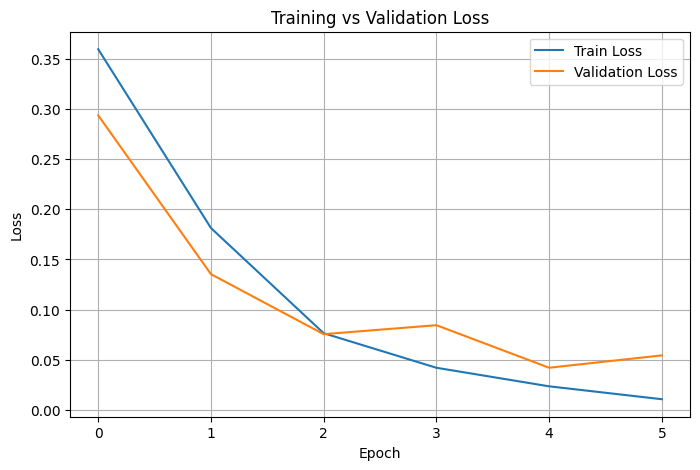

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
test_loss, test_acc = evaluate(model, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 0.5798
Test Accuracy: 0.8429


In [ ]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        preds = model(xb).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))


Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.99      0.59      0.74       234
   PNEUMONIA       0.80      1.00      0.89       390

    accuracy                           0.84       624
   macro avg       0.90      0.79      0.81       624
weighted avg       0.87      0.84      0.83       624



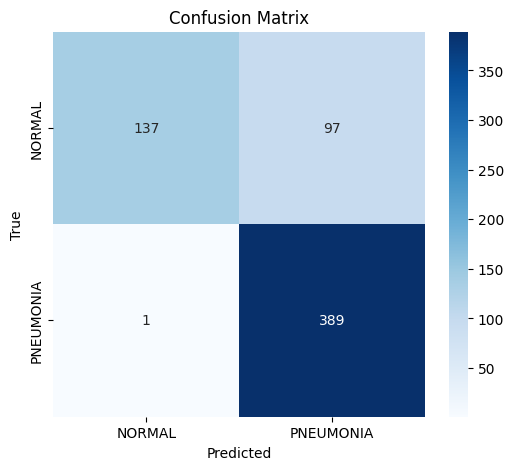

In [ ]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm, annot=True, fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
os.makedirs("checkpoints", exist_ok=True)
torch.save(model.state_dict(), "checkpoints/linear_eval_simclr_cxr.pt")
print("✅ Model saved")

In [ ]:
infer_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],
                         std=[0.229,0.224,0.225]),
])

In [ ]:

def predict_single(img_path):
    img = Image.open(img_path).convert("RGB")
    x = infer_transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1)[0]

    return {
        "prediction": class_names[probs.argmax().item()],
        "probabilities": {
            class_names[i]: float(probs[i]) for i in range(len(class_names))
        }
    }


In [ ]:
result = predict_single("/content/images.jpeg") #Normal
result2 = predict_single("/content/images (1).jpeg")# Pneumonia
result3 = predict_single("/content/images (2).jpeg") #Pneumonia
result4 = predict_single("/content/images (4) .jpg") # Normal
print(result)
print(result2)
print(result3)
print(result4)
